Forward pass:  d = 17.0
Gradients:
  d.grad = 1.0
  a.grad = 10.0   (expected: c = 10.0)
  b.grad = 1.0   (expected: 1.0)
  c.grad = 2.0   (expected: a = 2.0)


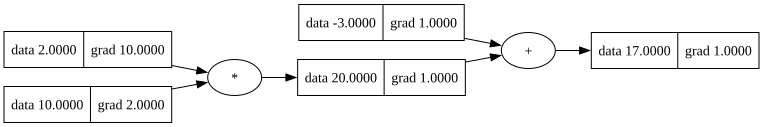

In [ ]:
"""
Advanced Micrograd Autograd Engine with Subtraction, Division, Power, and Exp.
"""

import math
import os
from graphviz import Digraph
from IPython.display import display


# ---------------------------------------------------------------------------
# Windows PATH fix for Graphviz
# ---------------------------------------------------------------------------
GRAPHVIZ_BIN = r"C:\Program Files\Graphviz\bin"
if os.path.isdir(GRAPHVIZ_BIN):
    os.environ["PATH"] = os.environ["PATH"] + os.pathsep + GRAPHVIZ_BIN


class Value:
    """A scalar value with autograd support for complex mathematical operations."""

    def __init__(self, data, _children=(), _op=""):
        self.data = float(data)
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    # -----------------------------------------------------------------------
    # Arithmetic Operations & Chain Rules
    # -----------------------------------------------------------------------

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), f"**{other}")

        def _backward():
            # d(x^n)/dx = n * x^(n-1)
            self.grad += (other * (self.data ** (other - 1))) * out.grad
        out._backward = _backward
        return out

    def __truediv__(self, other):  # self / other -> self * (other ** -1)
        other = other if isinstance(other, Value) else Value(other)
        return self * (other ** -1.0)

    def __neg__(self):  # -self
        return self * -1.0

    def __sub__(self, other):  # self - other
        return self + (-other)

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")

        def _backward():
            # d(e^x)/dx = e^x
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    # -----------------------------------------------------------------------
    # Reflected Operations (supports 2 + a, 2 * a, 2 / a, etc.)
    # -----------------------------------------------------------------------
    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __rsub__(self, other):
        return Value(other) - self

    def __rtruediv__(self, other):
        return Value(other) / self

    # -----------------------------------------------------------------------
    # Backpropagation Engine
    # -----------------------------------------------------------------------
    def backward(self):
        """Topological sort followed by reverse-mode chain rule application."""
        topo, visited = [], set()

        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)

        build(self)
        self.grad = 1.0  # dL/dL = 1.0
        for node in reversed(topo):
            node._backward()


# ---------------------------------------------------------------------------
# Graph Visualization Utilities
# ---------------------------------------------------------------------------
def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        dot.node(
            name=uid,
            label="{ data %.4f | grad %.4f }" % (n.data, n.grad),
            shape="record",
        )
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


# ---------------------------------------------------------------------------
# Complex Test Example
# ---------------------------------------------------------------------------
def main():
    # Inputs
    a = Value(3.0)
    b = Value(2.0)
    c = Value(4.0)

    # Complex expression combining multiplication, subtraction, division, power, and exp:
    # L = ((a^2 * c) - (b / a)) + exp(b)
    term1 = (a ** 2) * c
    term2 = b / a
    term3 = (b).exp()
    
    L = term1 - term2 + term3

    print(f"Forward pass: L = {L.data:.6f}")

    # Backpropagation
    L.backward()

    print("\nGradients computed via backpropagation:")
    print(f"  L.grad = {L.grad}")
    print(f"  a.grad = {a.grad}")
    print(f"  b.grad = {b.grad}")
    print(f"  c.grad = {c.grad}")

    # Render Graphviz diagram if running in a Jupyter notebook
    try:
        display(draw_dot(L))
    except NameError:
        print("\nGraphviz dot rendered (display() requires Jupyter Notebook environment).")


if __name__ == "__main__":
    main()